# Phase 7 : détection et comparaison (Q3, Q4, Q5)

Ce notebook construit un score de risque de 0 à 100 pour chaque transaction, le valide, compare les transactions signalées aux autres et produit la liste priorisée. Les fonctions sont dans `src/detection.py` et `src/comparisons.py`. Chaque étape est expliquée dans `docs/`.

Deux variantes :

- **sans étiquettes** (P7-01 à P7-07) : règles métier et anomalies. Les étiquettes de fraude ne servent à rien dans cette partie ;
- **avec étiquettes** (P7-08 et P7-11) : modèle supervisé, puis évaluation du score avec les étiquettes de fraude (`fraud_labels.json`, 67 % des transactions, P2-17).

## Chargement des données

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from src.load_data import load_clean_table
from src.charte import apply_style, save_figure, BLUE, ORANGE, NEUTRAL, TEXT_SECONDARY, THOUSANDS
from src.comparisons import rate_table, chi2_test, mann_whitney_test, holm_correction
from src.detection import (
    RULES, RULE_COLUMNS, rules_table, apply_rules, count_rules, BEHAVIOUR_FEATURES, behaviour_matrix,
    train_isolation_forest, anomaly_scores, risk_score, threshold_for_share, SHARES, threshold_summary,
    yearly_flag_rates, review_sample, main_reason, triggered_rules, ANOMALY_REASON, SHORT_LABELS, supervised_matrix,
    SUPERVISED_FEATURES, training_rows, train_supervised, precision_recall_at_shares,
    precision_recall_fixed_threshold, average_precision,
)

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 220)
RESULTATS = Path("data/resultats")
RESULTATS.mkdir(parents=True, exist_ok=True)

In [2]:
colonnes = sorted(set(
    ["id", "date", "client_id", "card_id", "amount", "use_chip", "mcc", "mcc_family", "merchant_country",
     "merchant_city", "card_brand", "card_type", "has_chip", "gender",
     "age_at_transaction", "credit_score", "yearly_income", "total_debt", "credit_limit", "year", "weekday",
     "is_weekend", "client_median_amount", "is_fraud"]
    + RULE_COLUMNS + BEHAVIOUR_FEATURES[2:]
))
df = load_clean_table("analysis", columns=colonnes)
profils = load_clean_table("client_profiles", columns=["client_id", "profil_nom"])
df["profil_nom"] = df["client_id"].map(profils.set_index("client_id")["profil_nom"]).astype("category")
CANAUX = {"Swipe Transaction": "Bande magnétique", "Chip Transaction": "Puce", "Online Transaction": "En ligne"}
df["canal"] = df["use_chip"].map(CANAUX).astype("category")
codes_lieu = np.where(df["is_online"] == 1, 0, np.where(df["is_foreign"] == 1, 1, 2)).astype("int8")
df["lieu"] = pd.Categorical.from_codes(codes_lieu, ["En ligne", "À l'étranger", "Sur place aux États-Unis"])
print(f"{len(df):,} transactions, {df.shape[1]} colonnes, {df.memory_usage(deep=True).sum() / 1e6:,.0f} Mo")

13,305,915 transactions, 43 colonnes, 1,239 Mo


## P7-01 : coder les règles métier

Une règle par signal du catalogue des indicateurs (P4-09). Chaque règle donne des points : 3 pour un signal fort, 2 pour un signal moyen, 1 pour un signal faible, trop fréquent pour compter seul. Les seuils sont fixés à partir des distributions de la phase 4, sans regarder les étiquettes de fraude.

Critère de fin : règles codées et comptées. Voir `docs/P7-01_regles_metier.md`.

In [3]:
rules_table()

,règle,points,condition
code,,,
R01,2 échecs d'authentification ou plus sur la carte en 24 h,3,card_auth_errors_24h >= 2
R02,échec d'authentification sur la transaction,2,has_auth_error == 1
R03,montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),3,amount_ratio >= 20 and amount >= 300
R04,rafale : 5 transactions ou plus de la carte dans l'heure précédente,3,card_tx_1h >= 5
R05,15 transactions ou plus de la carte dans les 24 heures précédentes,2,card_tx_24h >= 15
R06,premier achat du client dans ce pays (après 100 transactions),2,is_first_country == 1 and client_tx_rank >= 100
R07,achat sur place à l'étranger,2,is_foreign == 1
R08,nouveau commerçant dans une nouvelle catégorie (après 100 transactions),2,is_first_merchant == 1 and is_first_mcc == 1 and client_tx_rank >= 100
R09,achat de nuit (0 h à 5 h 59),1,is_night == 1


In [4]:
flags = apply_rules(df)
comptage = count_rules(flags)
print(f"Transactions touchées par au moins une règle : {int((flags['n_rules'] > 0).sum()):,}")
print(f"Transactions touchées par une règle à 3 points : "
      f"{int(flags[[r[0] for r in RULES if r[2] == 3]].max(axis=1).sum()):,}")
comptage

Transactions touchées par au moins une règle : 3,661,140
Transactions touchées par une règle à 3 points : 76,369


,règle,points,transactions touchées,part_%
code,,,,
R01,2 échecs d'authentification ou plus sur la carte en 24 h,3,1602,0.012
R02,échec d'authentification sur la transaction,2,53977,0.406
R03,montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),3,41570,0.312
R04,rafale : 5 transactions ou plus de la carte dans l'heure précédente,3,32978,0.248
R05,15 transactions ou plus de la carte dans les 24 heures précédentes,2,13082,0.098
R06,premier achat du client dans ce pays (après 100 transactions),2,4135,0.031
R07,achat sur place à l'étranger,2,89006,0.669
R08,nouveau commerçant dans une nouvelle catégorie (après 100 transactions),2,67568,0.508
R09,achat de nuit (0 h à 5 h 59),1,770383,5.790


In [5]:
flags["rule_points"].clip(upper=8).value_counts().sort_index().rename("transactions (8 = 8 points ou plus)")

0    9644775
1    3173967
2     339657
3     100029
4      29763
5      11422
6       5015
7        820
8        467
Name: transactions (8 = 8 points ou plus), dtype: int64

**Constats**

- Les 13 règles sont codées : 4 à 3 points, 6 à 2 points et 3 à 1 point. Chaque règle correspond à un signal du catalogue (P4-09).
- La règle des échecs d'authentification est fixée à 2 échecs ou plus en 24 heures (1 602 transactions) : avec 3 échecs, comme dans l'exemple de Jira, elle ne toucherait que 22 transactions (P4-06).
- Les règles à 3 points restent rares : de 392 transactions (hors validité de la carte) à 41 570 (montant au moins 20 fois plus élevé que d'habitude). Ensemble, elles touchent 76 369 transactions.
- Les règles à 1 point sont fréquentes : achat en ligne (11,752 %), montant rond (10,146 %), achat de nuit (5,790 %). Seules, elles ne suffisent pas à signaler une transaction.
- 3 661 140 transactions déclenchent au moins une règle. 9 644 775 n'en déclenchent aucune, et 467 cumulent 8 points ou plus.

## P7-02 : détecter les anomalies avec Isolation Forest

Isolation Forest isole chaque transaction par des coupes au hasard : une transaction atypique est isolée en peu de coupes. Le modèle apprend sur un échantillon de 500 000 transactions (la mémoire ne permet pas tout d'un coup), puis donne un score d'anomalie à toutes les transactions.

Variables de comportement : montant et rapport au montant habituel (en logarithme), activité de la carte dans l'heure et dans les 24 heures, échecs d'authentification, heure, achat en ligne ou à l'étranger, premières fois, échec sur la transaction.

Critère de fin : score calculé pour toutes les transactions. Voir `docs/P7-02_isolation_forest.md`.

In [6]:
x = behaviour_matrix(df)
debut = time.perf_counter()
modele_if = train_isolation_forest(x)
anomalie = anomaly_scores(modele_if, x)
print(f"Apprentissage et calcul : {time.perf_counter() - debut:.0f} s")
print(f"Scores calculés : {len(anomalie):,} sur {len(df):,} transactions ; valeurs vides : {int(np.isnan(anomalie).sum())}")
print("Critère de fin validé :", len(anomalie) == len(df) and not np.isnan(anomalie).any())
pd.Series(anomalie).describe(percentiles=[0.5, 0.99, 0.999]).round(4)

Apprentissage et calcul : 88 s
Scores calculés : 13,305,915 sur 13,305,915 transactions ; valeurs vides : 0
Critère de fin validé : True


count    1.330592e+07
mean     4.054000e-01
std      6.090000e-02
min      3.390000e-01
50%      3.829000e-01
99%      6.260000e-01
99.9%    6.877000e-01
max      7.907000e-01
dtype: float64

In [7]:
# Profil des 1 % de transactions les plus atypiques selon Isolation Forest, comparé aux autres
atypiques = anomalie >= np.quantile(anomalie, 0.99)
somme_toutes = x.sum(axis=0, dtype=np.float64)
somme_atypiques = x[atypiques].sum(axis=0, dtype=np.float64)
n_atypiques = int(atypiques.sum())
comparaison_if = pd.DataFrame({
    "1 % les plus atypiques": somme_atypiques / n_atypiques,
    "autres transactions": (somme_toutes - somme_atypiques) / (len(x) - n_atypiques),
}, index=BEHAVIOUR_FEATURES).round(3)
del x
comparaison_if

,1 % les plus atypiques,autres transactions
log_amount,3.773,2.900
log_amount_ratio,0.867,-0.147
card_tx_1h,0.825,0.270
card_tx_24h,3.853,1.891
card_auth_errors_24h,0.138,0.008
hour,12.971,12.384
is_online,0.200,0.117
is_foreign,0.078,0.006
is_first_merchant,0.767,0.019
is_first_mcc,0.679,0.000


**Constats**

- Isolation Forest apprend sur 500 000 transactions et note les 13 305 915 transactions en 88 s, sans valeur vide : le critère de fin est validé.
- Le score d'anomalie a une médiane de 0,3829. Il vaut 0,6260 au quantile 99 %, et 0,7907 au maximum.
- Le 1 % de transactions les plus atypiques se distingue surtout par les premières fois : 0,767 sont un premier achat chez ce commerçant (contre 0,019 pour les autres) et 0,679 dans une nouvelle catégorie (contre 0,000).
- Elles ont aussi un montant plus élevé et plus éloigné du montant habituel, plus d'activité sur la carte (3,853 transactions en 24 heures contre 1,891) et plus d'achats à l'étranger (0,078 contre 0,006).

## P7-03 : construire le score de risque

Le score combine les deux approches, à parts égales :

- **partie règles** : points des règles déclenchées, plafonnés à 8, ramenés entre 0 et 1 ;
- **partie anomalies** : rang de la transaction selon le score d'Isolation Forest, entre 0 et 1.

Score = 100 × (0,5 × partie règles + 0,5 × partie anomalies). Seuil de signalement retenu : le 1 % le plus risqué.

Critère de fin : score et seuil documentés. Voir `docs/P7-03_score_risque.md`.

In [8]:
df["rule_points"] = flags["rule_points"].to_numpy()
df["anomaly_pct"] = pd.Series(anomalie).rank(pct=True).to_numpy().astype("float32")
df["risk_score"] = risk_score(df["rule_points"], anomalie)
seuils = {share: threshold_for_share(df["risk_score"], share) for share in SHARES}
seuil_1 = seuils[0.01]
df["signalee"] = (df["risk_score"] >= seuil_1).astype("int8")
print(f"Seuil retenu (1 % le plus risqué) : score de {seuil_1:.2f} ou plus")
print(f"Transactions signalées : {int(df['signalee'].sum()):,}")
df["risk_score"].describe(percentiles=[0.5, 0.9, 0.99, 0.995, 0.999]).round(2)

Seuil retenu (1 % le plus risqué) : score de 62.42 ou plus
Transactions signalées : 133,075


count    13305915.00
mean           27.05
std            16.47
min             0.00
50%            26.04
90%            48.61
99%            62.42
99.5%          68.42
99.9%          81.11
max           100.00
Name: risk_score, dtype: float64

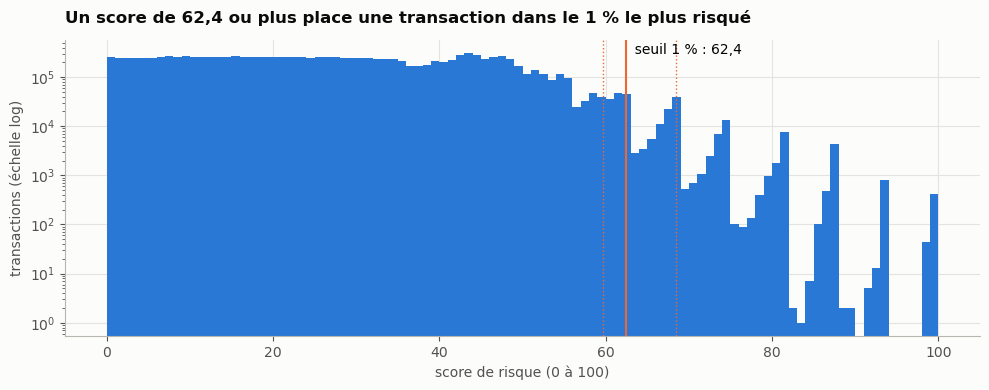

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df["risk_score"], bins=100, color=BLUE)
ax.set_yscale("log")
for share, couleur in zip(SHARES, [ORANGE, ORANGE, ORANGE]):
    ax.axvline(seuils[share], color=couleur, linewidth=1.5 if share == 0.01 else 1, linestyle="-" if share == 0.01 else ":")
ax.text(seuil_1, ax.get_ylim()[1] * 0.5, f"  seuil 1 % : {seuil_1:.1f}".replace(".", ","), color="black")
ax.set_xlabel("score de risque (0 à 100)")
ax.set_ylabel("transactions (échelle log)")
ax.set_title('Un score de 62,4 ou plus place une transaction dans le 1 % le plus risqué')
fig.tight_layout()
save_figure(fig, "P7-03_score_risque")
plt.show()

**Constats**

- Le seuil du 1 % le plus risqué est un score de 62,42. 133 075 transactions sont signalées.
- Le score médian est de 26,04. Il vaut 48,61 au quantile 90 %, 68,42 au quantile 99,5 % et 81,11 au quantile 99,9 %.
- La partie anomalies donne au plus 50 points : sans aucune règle déclenchée, une transaction ne peut pas atteindre le seuil.
- Le graphique montre des pics au-dessus du seuil : chacun correspond à un nombre de points de règles.

## P7-04 : valider le score

Trois contrôles : la charge de travail selon le seuil (0,5 %, 1 % et 2 %), la stabilité du taux de signalement d'une année à l'autre, et une revue manuelle de 50 transactions signalées. La grille de revue est exportée dans `data/resultats/P7-04_grille_revue.csv`.

Critère de fin : grille de revue remplie et conclusion. Voir `docs/P7-04_validation_score.md`.

In [10]:
threshold_summary(df, df["risk_score"].to_numpy())

,score minimal,transactions signalées,clients signalés,part des clients actifs_%,cartes signalées,signalements par jour
seuil,,,,,,
0.5 %,68.42,66562,1219,100.0,3819,18.5
1 %,62.42,133075,1219,100.0,3950,37.1
2 %,59.72,266128,1219,100.0,4012,74.1


In [11]:
stabilite = yearly_flag_rates(df["year"], df["risk_score"].to_numpy())
print("Écart relatif entre les années (écart-type / moyenne) :")
print((stabilite.std() / stabilite.mean()).round(2).to_string())
stabilite

Écart relatif entre les années (écart-type / moyenne) :
seuil 0.5 %    0.47
seuil 1 %      0.26
seuil 2 %      0.31


,seuil 0.5 %,seuil 1 %,seuil 2 %
year,,,
2010,1.113,1.683,3.661
2011,0.670,1.185,2.359
2012,0.533,1.023,1.986
2013,0.495,0.985,1.916
2014,0.422,0.908,1.784
2015,0.422,0.918,1.756
2016,0.381,0.874,1.687
2017,0.342,0.849,1.663
2018,0.345,0.811,1.648


In [12]:
df["raison_principale"] = main_reason(flags)
signalees = df[df["signalee"] == 1].copy()
signalees["regles"] = triggered_rules(flags.loc[signalees.index])

def fr2(x, decimales=2):
    return f"{x:.{decimales}f}".replace(".", ",")

def lecture(r):
    morceaux = [f"{r['canal'].lower()}, {r['mcc_family']}", f"{fr2(r['amount'])} $"]
    if pd.notna(r["amount_ratio"]) and r["amount"] > 0:
        morceaux.append(f"{fr2(r['amount_ratio'], 1)} fois le montant habituel ({fr2(r['client_median_amount'])} $)")
    morceaux.append(f"{r['date']:%Y-%m-%d %H:%M}")
    if r["is_foreign"] == 1:
        morceaux.append(f"à l'étranger ({r['merchant_country']})")
    if r["card_tx_1h"] > 0 or r["card_tx_24h"] > 0:
        morceaux.append(f"{r['card_tx_1h']} transactions de la carte dans l'heure, {r['card_tx_24h']} en 24 h")
    if r["card_auth_errors_24h"] > 0 or r["has_auth_error"] == 1:
        morceaux.append(f"{r['card_auth_errors_24h']} échecs d'authentification en 24 h"
                        + (", échec sur cette transaction" if r["has_auth_error"] == 1 else ""))
    premieres = [nom for col, nom in [("is_first_merchant", "commerçant"), ("is_first_mcc", "catégorie"),
                                      ("is_first_country", "pays")] if r[col] == 1]
    if premieres and r["client_tx_rank"] >= 100:
        morceaux.append("première fois : " + ", ".join(premieres))
    return " ; ".join(morceaux)

grille = review_sample(signalees, n=50)
grille["lecture"] = grille.apply(lecture, axis=1)
grille_export = grille[["id", "risk_score", "raison_principale", "regles", "lecture"]].copy()
grille_export["avis"] = ""
grille_export["commentaire"] = ""
grille_export.to_csv(RESULTATS / "P7-04_grille_revue.csv", index=False, encoding="utf-8-sig")
print(f"Grille exportée : {len(grille_export)} transactions")
grille_export[["id", "risk_score", "regles", "lecture"]]

Grille exportée : 50 transactions


,id,risk_score,regles,lecture
6925333,15904899,87.328,"R04, R05, R10","en ligne, Transport, carburant et automobile ; 75,02 $ ; 1,4 fois le montant..."
6752587,15693460,81.218,"R03, R08","bande magnétique, Transport, carburant et automobile ; 458,15 $ ; 112,3 fois..."
1924132,9797474,81.214,"R03, R08","bande magnétique, Industrie et fabrication ; 867,60 $ ; 71,8 fois le montant..."
5576984,14251992,81.175,"R03, R08","bande magnétique, Transport, carburant et automobile ; 327,17 $ ; 29,0 fois ..."
7165872,16200267,81.159,"R04, R05","puce, Alimentation ; -69,00 $ ; 2015-06-07 09:45 ; 5 transactions de la cart..."
4759800,13254009,80.508,"R03, R09, R11","bande magnétique, Voyage et hébergement ; 453,00 $ ; 21,1 fois le montant ha..."
2784369,10845684,74.917,"R08, R10, R11","en ligne, Voyage et hébergement ; 481,00 $ ; 12,4 fois le montant habituel (..."
3080716,11206846,74.795,"R08, R10, R11","en ligne, Voyage et hébergement ; 185,00 $ ; 5,5 fois le montant habituel (3..."
6726006,15660650,74.623,"R02, R09, R10","en ligne, Loisirs, culture et divertissement ; 17,66 $ ; 0,3 fois le montant..."
9238370,18742487,74.422,"R04, R11","puce, Alimentation ; 50,00 $ ; 0,9 fois le montant habituel (58,33 $) ; 2016..."


**Constats**

- **Charge de travail.** Au seuil de 0,5 %, 66 562 transactions sont signalées, soit 18,5 par jour en moyenne. Au seuil de 1 %, 133 075 (37,1 par jour). Au seuil de 2 %, 266 128 (74,1 par jour).
- Sur dix ans, les 1 219 clients actifs ont tous au moins une transaction signalée, quel que soit le seuil. Le nombre de cartes signalées va de 3 819 (0,5 %) à 4 012 (2 %).
- **Stabilité.** Au seuil de 1 %, le taux de signalement baisse de 1,683 % en 2010 à 0,811 % en 2018, puis 0,825 % en 2019. L'écart relatif entre les années vaut 0,26 (0,47 au seuil de 0,5 %). Le score signale donc deux fois plus en 2010 qu'en 2019. Explication probable : les « premières fois » (R08 et Isolation Forest) sont plus nombreuses au début des historiques.
- **Revue manuelle.** La grille de 50 transactions est exportée, puis remplie dans `docs/P7-04_validation_score.md` : 21 transactions jugées plausibles, 18 douteuses et 11 faux positifs probables. Les 11 faux positifs probables sont des rafales (R04) avec un montant habituel ou un remboursement.
- **Conclusion.** Le seuil de 1 % donne une charge de travail réaliste (37 transactions par jour). La règle des rafales produit la plupart des faux positifs, et le seuil doit être recalculé chaque année pour rester stable.

## P7-05 : comparer les transactions signalées aux autres (Q3)

Les transactions signalées au seuil de 1 % sont comparées aux autres, seulement sur des variables qui n'ont pas servi au signalement (le montant, l'heure, le canal et les indicateurs de la phase 4 sont donc exclus). Khi-deux pour les variables catégorielles, Mann-Whitney pour les variables numériques, dont les montants des clients et des cartes. Les p-valeurs sont corrigées avec la méthode de Holm, et chaque test donne sa taille d'effet.

Critère de fin : tableau des tests, p-valeurs et taille des écarts. Voir `docs/P7-05_comparaison_signalees.md`.

In [13]:
categorielles = ["card_brand", "card_type", "has_chip", "gender", "mcc_family", "is_weekend", "profil_nom"]
numeriques = {"credit_score": "score de crédit", "yearly_income": "revenu annuel", "total_debt": "dette",
              "credit_limit": "limite de crédit de la carte", "age_at_transaction": "âge à la transaction"}
lignes = [chi2_test(df, c, "signalee") for c in categorielles]
lignes += [mann_whitney_test(df[c], df["signalee"], nom) for c, nom in numeriques.items()]
tests = pd.DataFrame(lignes)
tests["p_valeur_Holm"] = holm_correction(tests["p_valeur"])
tests["significatif (5 %)"] = tests["p_valeur_Holm"] < 0.05
tests[["variable", "test", "statistique", "p_valeur", "p_valeur_Holm", "significatif (5 %)", "taille d'effet",
       "mesure", "lecture", "médiane groupe 1", "médiane groupe 0"]]

,variable,test,statistique,p_valeur,p_valeur_Holm,significatif (5 %),taille d'effet,mesure,lecture,médiane groupe 1,médiane groupe 0
0,card_brand,khi-deux,1.734700e+03,0.000000e+00,0.000000e+00,True,0.011,V de Cramér,négligeable,NaN,NaN
1,card_type,khi-deux,3.361300e+03,0.000000e+00,0.000000e+00,True,0.016,V de Cramér,négligeable,NaN,NaN
2,has_chip,khi-deux,1.919000e+02,1.209167e-43,3.627501e-43,True,0.004,V de Cramér,négligeable,NaN,NaN
3,gender,khi-deux,3.630000e+01,1.713438e-09,3.426876e-09,True,0.002,V de Cramér,négligeable,NaN,NaN
4,mcc_family,khi-deux,4.978955e+05,0.000000e+00,0.000000e+00,True,0.193,V de Cramér,faible,NaN,NaN
5,is_weekend,khi-deux,6.000000e-01,4.302499e-01,4.302499e-01,False,0.000,V de Cramér,négligeable,NaN,NaN
6,profil_nom,khi-deux,7.586200e+03,0.000000e+00,0.000000e+00,True,0.024,V de Cramér,négligeable,NaN,NaN
7,score de crédit,Mann-Whitney,8.420084e+11,4.897720e-135,2.448860e-134,True,-0.039,rang-bisériale,négligeable,713.0,716.0
8,revenu annuel,Mann-Whitney,9.583658e+11,0.000000e+00,0.000000e+00,True,0.093,rang-bisériale,négligeable,43133.0,41069.0
9,dette,Mann-Whitney,9.493272e+11,0.000000e+00,0.000000e+00,True,0.083,rang-bisériale,négligeable,57727.0,51679.0


In [14]:
# Pour information seulement : le montant a servi au signalement (règle R03 et Isolation Forest)
montants = df.groupby("signalee")["amount"].describe(percentiles=[0.5, 0.9])[["count", "50%", "90%", "mean"]]
montants.index = ["autres", "signalées"]
montants.round(2)

,count,50%,90%,mean
autres,13172840.0,28.68,102.65,41.17
signalées,133075.0,85.00,642.36,221.41


**Constats**

- 12 tests comparent les transactions signalées aux autres, sur des variables qui n'ont pas servi au signalement.
- Après la correction de Holm, 11 tests sur 12 sont significatifs. Seul le week-end ne l'est pas (p = 0,430).
- Mais presque toutes les tailles d'effet sont négligeables : V de Cramér de 0,002 à 0,024, corrélation rang-bisériale de -0,039 à 0,093. Les écarts sont significatifs à cause du nombre de lignes, pas parce qu'ils comptent.
- Une seule variable a un effet faible, mais réel : la famille de commerçants (V de Cramér de 0,193).
- Les clients et les cartes des transactions signalées ressemblent aux autres : score de crédit médian de 713 contre 716, âge de 46 ans contre 47, revenu de 43 133 $ contre 41 069 $.
- Pour information (variable utilisée par le score) : le montant médian est de 85,00 $ pour les transactions signalées, contre 28,68 $ pour les autres.

## P7-06 : identifier les caractéristiques liées au risque (Q4)

Taux de signalement (seuil 1 %) par profil de client, type et marque de carte, canal, famille de commerçants, lieu et heure. Le rapport compare chaque taux au taux global de 1 % : 2 veut dire deux fois plus de signalements que la moyenne.

Prudence avec les informations des cartes : elles décrivent la situation de février 2020, pas celle du jour de la transaction (P2-12).

Critère de fin : tableau des taux et graphique. Voir `docs/P7-06_caracteristiques_risque.md`.

In [15]:
for col, titre in [("profil_nom", "profil de client"), ("card_type", "type de carte"), ("card_brand", "marque de carte"),
                   ("canal", "canal"), ("lieu", "lieu")]:
    print(f"Par {titre} :")
    print(rate_table(df, col, "signalee").sort_values("taux_%", ascending=False).to_string())
    print()

Par profil de client :
                                transactions    cas  taux_%  écart_points  rapport
profil_nom                                                                        
Acheteurs en ligne très actifs       2319470  30774   1.327         0.327     1.33
Clients aisés et voyageurs           3670782  44508   1.212         0.212     1.21
Clients sans dette                    711056   5715   0.804        -0.196     0.80
Clients courants                     6530116  51822   0.794        -0.207     0.79
Revenu suspect (non classé)            74491    256   0.344        -0.656     0.34

Par type de carte :
                 transactions    cas  taux_%  écart_points  rapport
card_type                                                          
Credit                4109189  48024   1.169         0.169     1.17
Debit                 8280996  80258   0.969        -0.031     0.97
Debit (Prepaid)        915730   4793   0.523        -0.477     0.52

Par marque de carte :
            

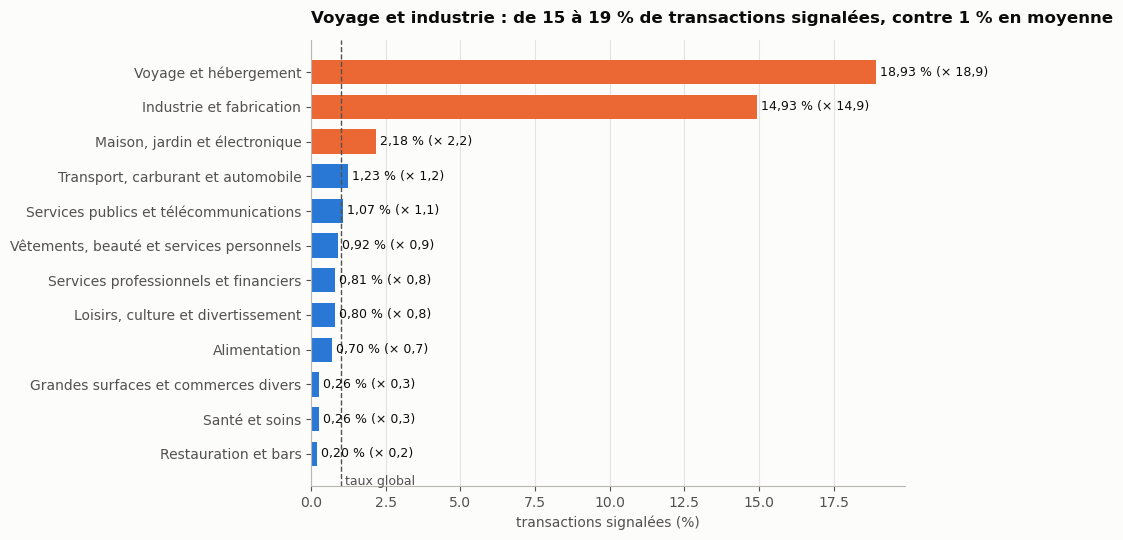

,transactions,cas,taux_%,écart_points,rapport
mcc_family,,,,,
Voyage et hébergement,52026,9850,18.933,17.933,18.93
Industrie et fabrication,150735,22499,14.926,13.926,14.92
"Maison, jardin et électronique",352851,7685,2.178,1.178,2.18
"Transport, carburant et automobile",3352312,41318,1.233,0.232,1.23
Services publics et télécommunications,626682,6683,1.066,0.066,1.07
"Vêtements, beauté et services personnels",265742,2434,0.916,-0.084,0.92
Services professionnels et financiers,718301,5838,0.813,-0.187,0.81
"Loisirs, culture et divertissement",638844,5095,0.798,-0.203,0.80
Alimentation,3182334,22350,0.702,-0.298,0.70


In [16]:
par_famille = rate_table(df, "mcc_family", "signalee").sort_values("taux_%")
fig, ax = plt.subplots(figsize=(10, 5.5))
couleurs = [ORANGE if r >= 2 else BLUE for r in par_famille["rapport"]]
ax.barh(par_famille.index.astype(str), par_famille["taux_%"], color=couleurs, height=0.7)
ax.axvline(100 * df["signalee"].mean(), color=TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.text(100 * df["signalee"].mean(), -0.9, " taux global", color=TEXT_SECONDARY, fontsize=9)
for i, (taux, rapport) in enumerate(zip(par_famille["taux_%"], par_famille["rapport"])):
    ax.text(taux, i, f" {taux:.2f} % (× {rapport:.1f})".replace(".", ","), va="center", fontsize=9)
ax.set_xlabel("transactions signalées (%)")
ax.grid(axis="y", visible=False)
ax.set_title('Voyage et industrie : de 15 à 19 % de transactions signalées, contre 1 % en moyenne')
fig.tight_layout()
save_figure(fig, "P7-06_signalement_familles")
plt.show()
par_famille.sort_values("taux_%", ascending=False)

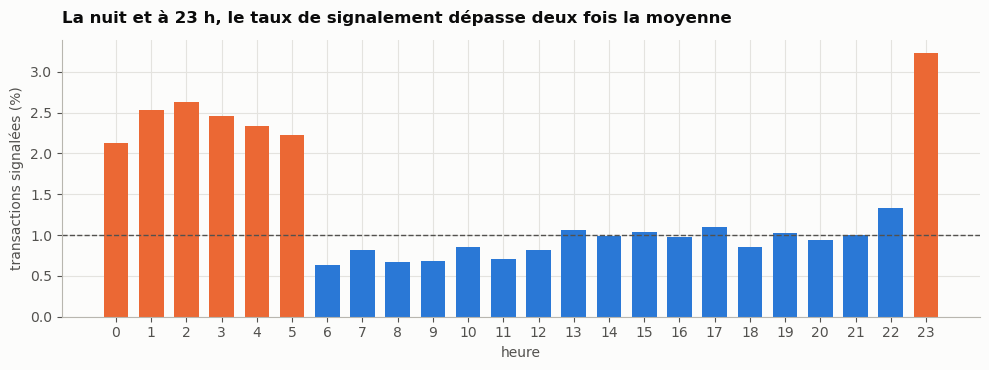

Heures où le taux dépasse deux fois le taux global :
      transactions   cas  taux_%  écart_points  rapport
hour                                                   
0           140582  2986   2.124         1.124     2.12
1           115586  2932   2.537         1.537     2.54
2           112787  2971   2.634         1.634     2.63
3           103478  2538   2.453         1.453     2.45
4           114985  2684   2.334         1.334     2.33
5           182965  4083   2.232         1.231     2.23
23          158877  5135   3.232         2.232     3.23


In [17]:
par_heure = rate_table(df, "hour", "signalee")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(par_heure.index, par_heure["taux_%"], color=[ORANGE if r >= 2 else BLUE for r in par_heure["rapport"]], width=0.7)
ax.axhline(100 * df["signalee"].mean(), color=TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.set_xticks(range(24))
ax.set_xlabel("heure")
ax.set_ylabel("transactions signalées (%)")
ax.set_title('La nuit et à 23 h, le taux de signalement dépasse deux fois la moyenne')
fig.tight_layout()
save_figure(fig, "P7-06_signalement_heures")
plt.show()
print("Heures où le taux dépasse deux fois le taux global :")
print(par_heure[par_heure["rapport"] >= 2].to_string())

**Constats**

- **Lieu et canal.** Le taux de signalement est de 19,437 % à l'étranger (19,43 fois le taux global de 1 %), 2,556 % en ligne et 0,650 % sur place aux États-Unis. Par canal : 2,561 % en ligne, 0,861 % par bande magnétique et 0,694 % par puce.
- **Famille de commerçants.** Voyage et hébergement (18,933 %) et industrie et fabrication (14,926 %) sont très au-dessus du taux global. La restauration (0,201 %), la santé (0,260 %) et les grandes surfaces (0,264 %) sont très en dessous.
- **Heure.** De 0 h à 5 h, le taux va de 2,124 % à 2,634 %. Il atteint 3,232 % à 23 h (3,23 fois le taux global).
- **Profil.** Les acheteurs en ligne très actifs (1,327 %) et les clients aisés et voyageurs (1,212 %) sont plus signalés que les clients courants (0,794 %) et les clients sans dette (0,804 %).
- **Carte.** Les cartes de crédit (1,169 %) et Amex (1,423 %) sont plus signalées que les cartes prépayées (0,523 %). Prudence : les informations des cartes datent de février 2020 (P2-12).
- Attention : l'étranger, le canal en ligne et la nuit sont aussi des règles du score (R07, R10, R09). Une partie de leur taux élevé vient donc de la construction du score. Les familles et les profils, eux, ne servent pas au score.

## P7-07 : produire la liste priorisée (Q5)

Les transactions signalées au seuil de 1 % sont triées par score, de la plus risquée à la moins risquée, avec la raison principale du signalement (la règle déclenchée qui a le plus de points, sinon l'anomalie détectée par Isolation Forest). La liste est exportée dans `data/resultats/P7-07_liste_priorisee.csv`.

Critère de fin : fichier exporté et commenté. Voir `docs/P7-07_liste_priorisee.md`.

In [18]:
liste = signalees.sort_values("risk_score", ascending=False)
liste.insert(0, "rang", np.arange(1, len(liste) + 1))
export = liste[["rang", "id", "date", "client_id", "card_id", "amount", "canal", "mcc_family", "merchant_city",
                "merchant_country", "risk_score", "raison_principale", "regles", "anomaly_pct"]]
export.to_csv(RESULTATS / "P7-07_liste_priorisee.csv", index=False, encoding="utf-8-sig")
print(f"Liste exportée : {len(export):,} transactions, "
      f"{(RESULTATS / 'P7-07_liste_priorisee.csv').stat().st_size / 1e6:.1f} Mo")
raisons = export["raison_principale"].value_counts()
print()
print(raisons.to_string())
export.head(10)

Liste exportée : 133,075 transactions, 26.9 Mo

R04 : rafale : 5 transactions ou plus de la carte dans l'heure précédente        32908
R03 : montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus)         26260
R08 : nouveau commerçant dans une nouvelle catégorie (après 100 transactions)    24901
R02 : échec d'authentification sur la transaction                                24382
R07 : achat sur place à l'étranger                                               12068
R05 : 15 transactions ou plus de la carte dans les 24 heures précédentes          4862
R06 : premier achat du client dans ce pays (après 100 transactions)               3885
R09 : achat de nuit (0 h à 5 h 59)                                                1949
R01 : 2 échecs d'authentification ou plus sur la carte en 24 h                    1595
R12 : transaction hors de la période de validité de la carte                       215
R10 : achat en ligne                                                              

,rang,id,date,client_id,card_id,amount,canal,mcc_family,merchant_city,merchant_country,risk_score,raison_principale,regles,anomaly_pct
9804310,1,19437322,2017-04-29 00:50:00,1527,2366,382.00,Puce,Voyage et hébergement,Islamabad,Pakistan,100.0,R06 : premier achat du client dans ce pays (après 100 transactions),"R06, R07, R08, R09, R11",0.999991
1098445,2,8793676,2010-11-20 23:04:00,1435,4294,498.00,Bande magnétique,Industrie et fabrication,Tapei,Taiwan,100.0,R03 : montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),"R03, R07, R08, R11",0.999990
344906,3,7887775,2010-04-14 23:33:00,1742,1155,387.00,Bande magnétique,"Transport, carburant et automobile",Rome,Italy,100.0,R03 : montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),"R03, R07, R08, R11",0.999990
3155899,4,11298346,2012-06-23 03:28:00,704,2945,256.00,Bande magnétique,Industrie et fabrication,Seoul,South Korea,100.0,R06 : premier achat du client dans ce pays (après 100 transactions),"R06, R07, R08, R09, R11",0.999993
244693,5,7767755,2010-03-16 04:00:00,419,3854,426.00,En ligne,"Transport, carburant et automobile",ONLINE,ONLINE,100.0,R03 : montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),"R02, R03, R08, R09, R10, R11",1.000000
3875677,6,12175144,2013-01-07 06:24:00,1467,3556,499.00,Bande magnétique,Industrie et fabrication,Devine,USA,100.0,R01 : 2 échecs d'authentification ou plus sur la carte en 24 h,"R01, R03, R08, R11",0.999990
107976,7,7604292,2010-02-02 22:50:00,1797,1127,97.61,Bande magnétique,Industrie et fabrication,Bangkok,Thailand,100.0,R04 : rafale : 5 transactions ou plus de la carte dans l'heure précédente,"R04, R05, R07, R08",0.999999
7394216,8,16479675,2015-08-05 16:58:00,1844,2854,442.64,En ligne,Industrie et fabrication,ONLINE,ONLINE,100.0,R03 : montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),"R02, R03, R08, R10",0.999995
958079,9,8623973,2010-10-11 08:39:00,1896,1124,1739.54,En ligne,Voyage et hébergement,ONLINE,ONLINE,100.0,R03 : montant au moins 20 fois plus élevé que d'habitude (300 $ ou plus),"R02, R03, R08, R10",0.999995
103388,10,7598785,2010-02-01 14:29:00,408,2515,126.57,Bande magnétique,Alimentation,Port au Prince,Haiti,100.0,R02 : échec d'authentification sur la transaction,"R02, R06, R07, R08",0.999993


In [19]:
# Scores enregistrés pour le tableau de bord (phase 8)
scores = pd.DataFrame({
    "id": df["id"].to_numpy(),
    "risk_score": df["risk_score"].astype("float32").to_numpy(),
    "rule_points": df["rule_points"].to_numpy(),
    "anomaly_pct": df["anomaly_pct"].to_numpy(),
    "flag_0_5": (df["risk_score"] >= seuils[0.005]).astype("int8").to_numpy(),
    "flag_1": df["signalee"].to_numpy(),
    "flag_2": (df["risk_score"] >= seuils[0.02]).astype("int8").to_numpy(),
    "main_reason": df["raison_principale"].astype("category").to_numpy(),
})
for code_regle, *_ in RULES:
    scores[code_regle] = flags[code_regle].to_numpy()
scores.to_parquet("data/clean/risk_scores.parquet", index=False, compression="zstd")
print(f"Scores enregistrés : {len(scores):,} lignes, {scores.shape[1]} colonnes")

Scores enregistrés : 13,305,915 lignes, 21 colonnes


**Constats**

- La liste priorisée compte 133 075 transactions, du score le plus haut au plus bas. Elle est exportée dans `data/resultats/P7-07_liste_priorisee.csv` (26,9 Mo, non versionné).
- Quatre raisons principales dominent : rafale dans l'heure (R04, 32 908), montant inhabituel (R03, 26 260), nouveau commerçant dans une nouvelle catégorie (R08, 24 901) et échec d'authentification (R02, 24 382).
- Aucune transaction n'est signalée par Isolation Forest seul : chacune a au moins une règle déclenchée.
- Les 10 premières transactions ont un score de 100,0. La plupart sont des achats à l'étranger (Pakistan, Italie, Haïti, Corée du Sud, Taïwan, Thaïlande) ou de gros achats en ligne (jusqu'à 1 739,54 $), avec 4 à 6 règles déclenchées chacune.
- Les scores des 13 305 915 transactions sont enregistrés pour le tableau de bord (`data/clean/risk_scores.parquet`).